# Forward-mode AD through the JAX solver

Goal: Differentiate a scalar of the final 1-D shallow-water state with respect to the Manning n by jax.jvp and check it against finite differences.

Prerequisite: [A 1-D mesh](../mesh/mesh_1d.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

import zoomy_core.model.boundary_conditions as BC
import zoomy_core.model.initial_conditions as IC
from zoomy_core.mesh import LSQMesh
from zoomy_core.model.models import SME
from zoomy_core.model.models.closures import ManningFriction, Newtonian, StressFree
from zoomy_core.numerics import NumericalSystemModel, ReconstructionSpec
from zoomy_core.systemmodel import SystemModel
from zoomy_jax.symsolver.solver import AdMode, SymbolicHyperbolicSolverJax

In [2]:
model = SME(
    level=0, dimension=2,
    closures=[Newtonian(), ManningFriction(), StressFree()],
    boundary_conditions=BC.BoundaryConditions(
        [BC.Extrapolation(tag="left"), BC.Extrapolation(tag="right")]),
)
sm = SystemModel.from_model(model)


def initial_state(x):
    h = 1.0 + 0.2 * np.exp(-(x[0] - 5.0) ** 2)
    return np.array([0.0, h, h])


sm.initial_conditions = IC.UserFunction(function=initial_state)
nsm = NumericalSystemModel.from_system_model(sm, reconstruction=ReconstructionSpec(order=1))
mesh = LSQMesh.create_1d(domain=(0.0, 10.0), n_inner_cells=100)

In [3]:
def objective(ad_mode, ad_checkpoints=16):
    solver = SymbolicHyperbolicSolverJax(time_end=0.5, dt=1e-2, mood=False,
                                         ad_mode=ad_mode, ad_checkpoints=ad_checkpoints)
    Q0, Qaux0 = solver.setup(mesh, nsm)
    q = solver.nsm.sm.roles.depth + 1
    V = solver.mesh.cell_volumes[:Q0.shape[1]]

    def final_state(p):
        return solver.run(Q0, solver.initial_aux(Q0, Qaux0, p), parameters=p)[1]

    def J(p):
        return jnp.sum(final_state(p)[q] ** 2 * V)

    return jax.jit(J), final_state, solver


J, final_state, solver = objective(AdMode.forward)
names = list(solver.rt.parameter_names)
i = names.index("n")
p0 = solver.parameters.at[i].set(0.05)
e = jnp.zeros_like(p0).at[i].set(1.0)

In [4]:
Q = np.asarray(final_state(p0))
forward = float(jax.jvp(J, (p0,), (e,))[1])
r = 1e-3 * float(p0[i])
central = float(J(p0 + r * e) - J(p0 - r * e)) / (2 * r)
print(f"J = {float(J(p0)):.8f}")
print(f"dJ/dn forward {forward:.8e}   central difference {central:.8e}")

J = 10.70960113
dJ/dn forward -1.00101431e+01   central difference -1.00101428e+01


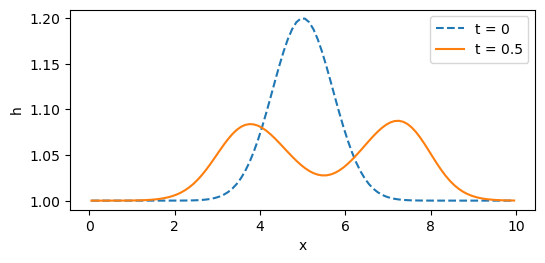

In [5]:
x = mesh.cell_centers[0, :mesh.n_inner_cells]
Q0 = np.array([initial_state([xi]) for xi in x]).T
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot(x, Q0[1], "--", label="t = 0")
ax.plot(x, Q[1], label="t = 0.5")
ax.set_xlabel("x")
ax.set_ylabel("h")
ax.legend()
plt.show()

In [6]:
assert abs(forward - central) / abs(forward) < 1e-5